#Анализ сингулярностей и дифференциальная кинематика робота М20П

Таблица Денавита-Хартенберга

\begin{array}{ccc}
& \theta & d & a & \alpha \\
1 & q_1 & d_0+d_1 & 0 & 0 \\\
2 & 0 & d_2 & a_2 & 90° \\
3 & 0 & d_3 & 0 & 0 \\
4 & q_4 & 0 & 0 & -90° \\
5 & q_5 & 0 & 0 & 90° \\
6 & q_6\ & d_G & 0 & 0
\end{array}

Определение параметров:

* $d_0, d_1$ - константы которые составляют высоту основания манипулятора
* $a_2$ - константа которая составляет вынос плеча
* $d_G$ - константа которая составляет длину инструмента
* $q_1$ - Поворот основания
* $d_2$ - выдвижение первого линейного привода
* $d_3$ - выдвижение второго линейного привода
* $q_4, q_5, q_6$ - параметры вращения кисти

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import display, Math

from matplotlib.animation import FuncAnimation

In [ ]:
# "Библиотека" для различных операций для манипуляторов
class RMath:

    @staticmethod
    def rx(theta):
        c, s = np.cos(theta), np.sin(theta)
        return np.array([[1, 0,  0, 0],
                         [0, c, -s, 0],
                         [0, s,  c, 0],
                         [0, 0,  0, 1]])

    @staticmethod
    def ry(theta):
        c, s = np.cos(theta), np.sin(theta)
        return np.array([[ c, 0, s, 0],
                         [ 0, 1, 0, 0],
                         [-s, 0, c, 0],
                         [ 0, 0, 0, 1]])

    @staticmethod
    def rz(theta):
        c, s = np.cos(theta), np.sin(theta)
        return np.array([[c, -s, 0, 0],
                         [s,  c, 0, 0],
                         [0,  0, 1, 0],
                         [0,  0, 0, 1]])

    @staticmethod
    def tran(x, y, z):
        T = np.eye(4)
        T[:3, 3] = [x, y, z]
        return T

    @staticmethod
    def dh_matrix(theta, d, a, alpha):
        return RMath.rz(theta) @ RMath.tran(0, 0, d) @ RMath.tran(a, 0, 0) @ RMath.rx(alpha)

    @staticmethod
    def extract_zyz(R):
        if np.abs(R[2, 2]) < 1.0 - 1e-10:
            q5 = np.arccos(R[2, 2])
            q4 = np.arctan2(R[1, 2], R[0, 2])
            q6 = np.arctan2(R[2, 1], -R[2, 0])
        else:
            q5 = 0.0 if R[2, 2] > 0 else np.pi
            q4 = np.arctan2(R[1, 0], R[0, 0])
            q6 = 0.0
        return np.array([q4, q5, q6])

    @staticmethod
    def generate_ik_input(x, y, z, x_rotate=0, y_rotate=0, z_rotate=0):
      x_rotate_rad = np.deg2rad(x_rotate)
      y_rotate_rad = np.deg2rad(y_rotate)
      z_rotate_rad = np.deg2rad(z_rotate)

      R = RMath.rx(x_rotate_rad) @ RMath.ry(y_rotate_rad) @ RMath.rz(z_rotate_rad)

      T_target = np.eye(4)
      T_target[:3, :3] = R[:3, :3]
      T_target[:3, 3] = [x, y, z]

      return T_target

    @staticmethod
    def print_jacobian(J):
        rows = []
        for row in J:
            rows.append(" & ".join(f"{v:.3f}" for v in row))
        matrix_latex = " \\\\ ".join(rows)

        display(Math(r"J = \begin{bmatrix}" + matrix_latex + r"\end{bmatrix}"))

        rank = np.linalg.matrix_rank(J, tol=1e-6)
        det = np.linalg.det(J)

        display(Math(r"\text{rank}(J) = " + str(rank)))
        display(Math(r"\det(J) = " + f"{det:.6f}"))

        if rank < 6:
            display(Math(r"\text{Сингулярность}"))
        else:
            display(Math(r"\text{Сингулярность отсутствует}"))

In [ ]:
# Класс робота М20П
class M20P:
    def __init__(self, d0=0.1, d1=0.1, a2=0.5, d_G = 0.3):
        self.d0 = d0 # Высота основания 0
        self.d1 = d1 # Высота основания 1
        self.a2 = a2 # Смещение плеча
        self.d_G = d_G # Длина инструмента

    def forward_kinematics(self, q):
        T01 = RMath.dh_matrix(q[0], self.d0 + self.d1, 0, 0)
        T12 = RMath.dh_matrix(0, q[1], self.a2, np.pi/2)
        T23 = RMath.dh_matrix(0, q[2], 0, 0)

        R_wrist = RMath.dh_matrix(q[3], 0, 0, -np.pi/2) @ RMath.dh_matrix(q[4], 0, 0, np.pi/2) @ RMath.dh_matrix(q[5], self.d_G, 0, 0);

        T_total = T01 @ T12 @ T23 @ R_wrist
        return T_total

    def inverse_kinematics(self, T_target):
        P_tip = T_target[:3, 3]
        R_target = T_target[:3, :3]
        P_wc = P_tip - self.d_G * R_target[:3, 2]

        x, y, z = P_wc
        R_xy = np.sqrt(x**2 + y**2)

        if R_xy < self.a2:
            return None

        q1 = np.arccos(self.a2/R_xy) + np.atan2(y, x)
        d3 = np.sqrt((x-self.a2*np.cos(q1))**2 + (y-self.a2*np.sin(q1))**2)
        d2 = z - self.d0 - self.d1

        T03 = self.forward_kinematics([q1, d2, d3, 0, 0, 0])
        R03 = T03[:3, :3]

        R_wrist = R03.T @ R_target
        q4, q5, q6 = RMath.extract_zyz(R_wrist)

        return [q1, d2, d3, q4, q5, q6]

    def jacobian(self, q):
        T01 = RMath.dh_matrix(q[0], self.d0 + self.d1, 0, 0)
        T12 = RMath.dh_matrix(0, q[1], self.a2, np.pi/2)
        T23 = RMath.dh_matrix(0, q[2], 0, 0)
        T34 = RMath.dh_matrix(q[3], 0, 0, -np.pi/2)
        T45 = RMath.dh_matrix(q[4], 0, 0, np.pi/2)
        T56 = RMath.dh_matrix(q[5], self.d_G, 0, 0)

        T = [np.eye(4), T01, T01@T12, T01@T12@T23,
            T01@T12@T23@T34, T01@T12@T23@T34@T45,
            T01@T12@T23@T34@T45@T56]

        pe = T[6][:3, 3] # Позиция конца инструмента
        J = np.zeros((6, 6))
        joint_types = ['R', 'L', 'L', 'R', 'R', 'R'] # Типы шаринров, где R-вращательный, L-линейный
        for i in range(6):
            z = T[i][:3, 2]
            p = T[i][:3, 3]
            if joint_types[i] == 'R':
                J[:3, i] = np.cross(z, pe - p)
                J[3:, i] = z
            else:
                J[:3, i] = z
                J[3:, i] = np.zeros(3)
        return J

    def numerical_jacobian(self, q, eps=1e-7):
        J = np.zeros((6, 6))

        T0 = self.forward_kinematics(q)
        p0 = T0[:3, 3]
        R0 = T0[:3, :3]

        for i in range(6):
            q_plus = q.copy()
            q_plus[i] += eps

            T_plus = self.forward_kinematics(q_plus)
            p_plus = T_plus[:3, 3]
            R_plus = T_plus[:3, :3]

            J[:3, i] = (p_plus - p0) / eps

            dR = (R_plus - R0) / eps
            S = dR @ R0.T
            J[3, i] = S[2, 1]
            J[4, i] = S[0, 2]
            J[5, i] = S[1, 0]
        return J

    def simulate_forward_differential_kimenatics(self, q0, q_speeds, dt, steps):
        q = np.array(q0, dtype=float)
        q_speeds = np.array(q_speeds, dtype=float)
        q_records = [q.copy()]
        endeffector_pos_records = [self.forward_kinematics(q)[:3, 3].copy()]
        for _ in range(steps):
            q += q_speeds * dt
            q_records.append(q.copy())
            endeffector_pos_records.append(self.forward_kinematics(q)[:3,3].copy())
        return np.array(q_records), np.array(endeffector_pos_records)

    def simulate_inverse_differential_kimenatics(self, q0, x_speeds, dt, steps, inversion_method="pseudoinverse"):
        q = np.array(q0, dtype=float)
        x_speeds = np.array(x_speeds, dtype=float)
        q_records = [q.copy()]
        endeffector_pos_records = [self.forward_kinematics(q)[:3, 3].copy()]

        for _ in range(steps):
            J = self.jacobian(q)
            n = len(q)

            if inversion_method == "pseudoinverse":
                J_inv = np.linalg.pinv(J)
                q_dot = J_inv @ x_speeds
            elif inversion_method == 'nullspace_manipulativity_damping':
                JJt = J @ J.T

                lambda_damping = 1e-3
                J_inv = J.T @ np.linalg.inv(JJt + lambda_damping * lambda_damping * np.eye(J.shape[0]))
                qdot_primary = J_inv @ x_speeds

                def manipulability(q):
                    J = self.jacobian(q)
                    return np.sqrt(max(np.linalg.det(J @ J.T), 0.0))

                def grad_manip(q, eps=1e-6):
                    g = np.zeros_like(q)
                    w0 = manipulability(q)
                    for i in range(len(q)):
                        dq = np.zeros_like(q)
                        dq[i] = eps
                        g[i] = (manipulability(q + dq) - w0) / eps
                    return g
                grad_w = grad_manip(q)
                P = np.eye(len(q)) - J_inv @ J
                k0 = 5.0
                q_dot = qdot_primary + P @ (k0 * grad_w)
            q = q + q_dot * dt
            q_records.append(q.copy())
            endeffector_pos_records.append(self.forward_kinematics(q)[:3,3].copy())
        return np.array(q_records), np.array(endeffector_pos_records)

    def visualize(self, q):
        T01 = RMath.dh_matrix(q[0], self.d0 + self.d1, 0, 0)
        T12_1 = T01 @ RMath.dh_matrix(0, q[1], 0, 0)
        T12_2 = T12_1 @ RMath.dh_matrix(0, 0, self.a2, np.pi/2)
        T23 = T12_2 @ RMath.dh_matrix(0, q[2], 0, 0)

        T34 = T23 @ RMath.dh_matrix(q[3], 0, 0, -np.pi/2)
        T45 = T34 @ RMath.dh_matrix(q[4], 0, 0, np.pi/2)
        T56 = T45 @ RMath.dh_matrix(q[5], self.d_G, 0, 0)

        p0 = np.array([0, 0, 0])          # Основание
        p1 = T01[:3, 3]                   # Мотор q1
        p2 = T12_1[:3, 3]                 # Линейный привод d2
        p3 = T12_2[:3, 3]                 # Плечо
        p4 = T23[:3, 3]                   # Линейный привод d3
        p_end = T56[:3, 3]                # Инструмент

        origin = p_end
        scale = 0.2
        x_axis = origin + T56[:3, 0] * scale
        y_axis = origin + T56[:3, 1] * scale
        z_axis = origin + T56[:3, 2] * scale

        points = np.array([p0, p1, p2, p3, p4, p_end])
        labels = ['Основание', 'Мотор q1', 'Линейный привод d2', 'Плечо', 'Линейный привод d3', "Инструмент"]

        fig = plt.figure(figsize=(12, 12))
        ax = fig.add_axes([0.2, 0.1, 0.6, 0.8], projection='3d', computed_zorder=False)
        ax.set_box_aspect((1, 1, 1))

        ax.plot(points[:-1,0], points[:-1,1], points[:-1,2], '-o', linewidth=4, markersize=10, color='coral', zorder=5)
        ax.plot(points[-2:, 0], points[-2:, 1], points[-2:, 2], '-o', linewidth=4, markersize=10, color='maroon', zorder=5)

        ax.quiver(origin[0], origin[1], origin[2], T56[0, 0], T56[1, 0], T56[2, 0], length=scale, color='red', linewidth=2, label='Ось X Инструмента', zorder=10)
        ax.quiver(origin[0], origin[1], origin[2], T56[0, 1], T56[1, 1], T56[2, 1], length=scale, color='green', linewidth=2, label='Ось Y Инструмента', zorder=10)
        ax.quiver(origin[0], origin[1], origin[2], T56[0, 2], T56[1, 2], T56[2, 2], length=scale, color='blue', linewidth=2, label='Ось Z Инструмента', zorder=10)

        for i, p in enumerate(points):
            text = f"{labels[i]} ({p[0]:.2f}, {p[1]:.2f}, {p[2]:.2f})"
            ax.text(p[0], p[1], p[2], text, fontsize=8, fontweight='bold', zorder=15, ha='center', va='bottom')

        ax.set_xlabel('X (м)')
        ax.set_ylabel('Y (м)')
        ax.set_zlabel('Z (м)')
        ax.set_title(f"Параметры приводов: [{round(np.rad2deg(q[0]),2)}°, {round(q[1],2)}м, {round(q[2],2)}м, {round(np.rad2deg(q[3]),2)}°, {round(np.rad2deg(q[4]),2)}°, {round(np.rad2deg(q[5]),2)}°]")

        max_range = np.array([points[:,0].max()-points[:,0].min(),
                              points[:,1].max()-points[:,1].min(),
                              points[:,2].max()-points[:,2].min()]).max() / 2.0
        max_range *= 1.3
        mid_x = (points[:,0].max()+points[:,0].min()) * 0.5
        mid_y = (points[:,1].max()+points[:,1].min()) * 0.5
        ax.set_xlim(mid_x - max_range, mid_x + max_range)
        ax.set_ylim(mid_y - max_range, mid_y + max_range)
        ax.set_zlim(0, points[:,2].max() * 1.3)

        ax.plot_trisurf([mid_x-max_range, mid_x+max_range, mid_x-max_range, mid_x+max_range],
                [mid_y-max_range, mid_y-max_range, mid_y+max_range, mid_y+max_range],
                [0, 0, 0, 0], color='white', antialiased=False, zorder=1)

        plt.legend()
        plt.show()

    def plot_workspace(self):
        q1_range = np.linspace(0, 2*np.pi, 100)
        d2_range = np.linspace(0, 1, 10)
        d3_range = np.linspace(0, 2, 20)

        x_points, y_points, z_points = [], [], []

        for q1 in q1_range:
            for d2 in d2_range:
                for d3 in d3_range:
                    T = self.forward_kinematics([q1, d2, d3, 0, 0, 0])
                    x_points.append(T[0,3])
                    y_points.append(T[1,3])
                    z_points.append(T[2,3])

        fig = plt.figure(figsize=(10, 10))
        ax = fig.add_subplot(111, projection='3d')
        ax.scatter(x_points, y_points, z_points,c=z_points, s=50, alpha=0.1, cmap='magma')
        ax.set_title("Рабочая область")

        ax.set_zlim(self.d0+self.d1, max(z_points) * 1.3)

        plt.show()

In [ ]:
bot = M20P()

<h1>Первый случай сингулярности:

Линейный шарнир d3 вытянут на 0 метров.

Стоит заметить, что такое вряд ли будет возможно физически - втянуть руку так, чтобы запястья лежало ровно на плече (у которого длина $a_2$). Но математически такой случай приведёт к сингулярности

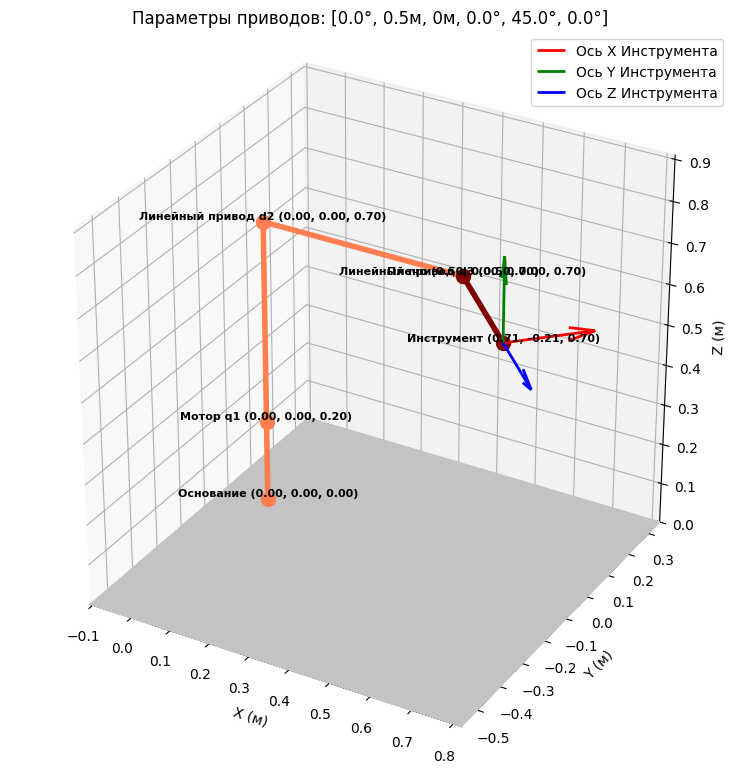


Аналитическая матрица Якоби:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Численная матрица Якоби:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
bot.visualize([0, 0.5, 0, 0, np.pi/4, 0])
print("\nАналитическая матрица Якоби:")
RMath.print_jacobian(bot.jacobian([0, 0.5, 0, 0, np.pi/4, 0]))

print("\nЧисленная матрица Якоби:")
RMath.print_jacobian(bot.numerical_jacobian([0, 0.5, 0, 0, np.pi/4, 0]))

<h1>Второй случай сингулярности:

Сингулярность в кисти



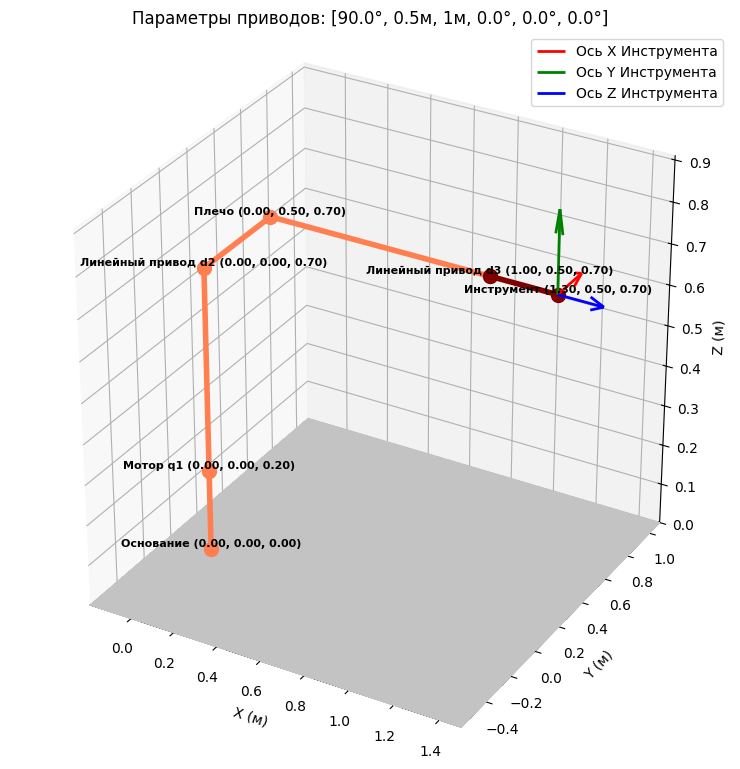


Аналитическая матрица Якоби:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Численная матрица Якоби:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
bot.visualize([np.pi/2, 0.5, 1, 0, 0, 0])
print("\nАналитическая матрица Якоби:")
RMath.print_jacobian(bot.jacobian([np.pi/2, 0.5, 1, 0, 0, 0]))

print("\nЧисленная матрица Якоби:")
RMath.print_jacobian(bot.numerical_jacobian([np.pi/2, 0.5, 1, 0, 0, 0]))

<h1>Обе сингулярности сразу:



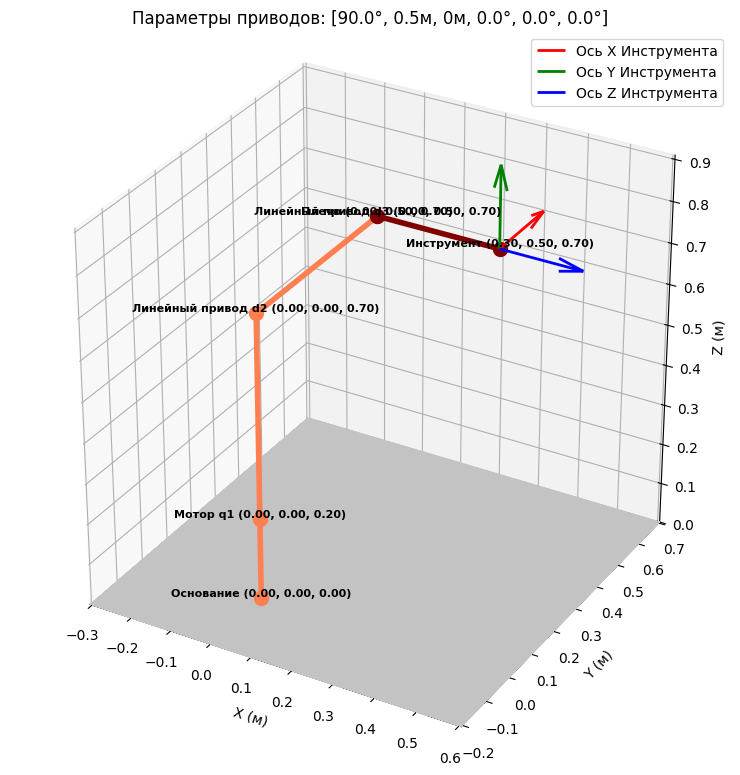


Аналитическая матрица Якоби:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Численная матрица Якоби:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
bot.visualize([np.pi/2, 0.5, 0, 0, 0, 0])
print("\nАналитическая матрица Якоби:")
RMath.print_jacobian(bot.jacobian([np.pi/2, 0.5, 0, 0, 0, 0]))

print("\nЧисленная матрица Якоби:")
RMath.print_jacobian(bot.numerical_jacobian([np.pi/2, 0.5, 0, 0, 0, 0]))

In [ ]:
def plot_FDKsimulation(t, history_q, history_ee, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(title)

    ax1.plot(t, history_q)
    ax1.set_title("Обобщённые координаты шарниров")
    ax1.set_xlabel("t")
    ax1.legend(['q1', 'd2', 'd3', 'q4', 'q5', 'q6'])

    ax2.plot(t, history_ee)
    ax2.set_title("Позиция инструмента")
    ax2.set_xlabel("t")
    ax2.legend(['x', 'y', 'z'])

    plt.tight_layout()
    plt.show()

<h2>Далее приведена симуляция прямой дифференциальной кинематики при $dt=0.1$ и $dt=0.5$

Начальные параметры шарниров:
$q = [0,0.5,0.9,0,0,0]$

Скорости шарниров:
$\dot{q} = [1, 0.75, 0.55, 0.45, 0.7, -0.3]$

$dt = 0.1$:

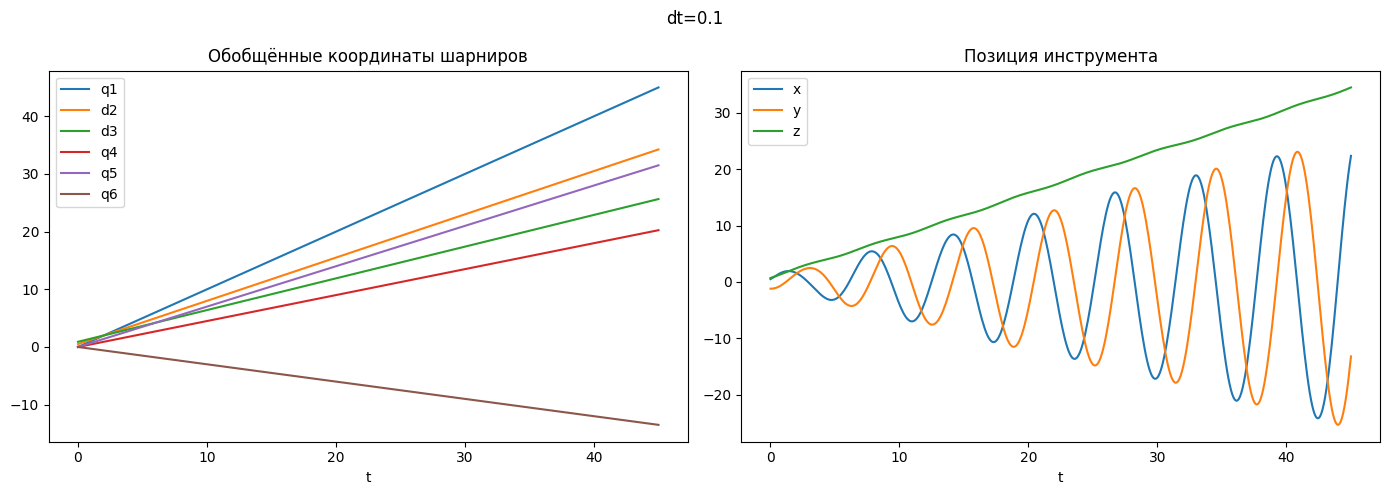

In [ ]:
q0    = [0,0.5,0.9,0,0,0]
q_dot = [1, 0.75, 0.55, 0.45, 0.7, -0.3]

q_hist, ee_hist = bot.simulate_forward_differential_kimenatics(q0, q_dot, 0.1, int(45/0.1))
plot_FDKsimulation(np.arange(len(q_hist)) * 0.1, q_hist, ee_hist, "dt=0.1")

$dt = 0.5$:

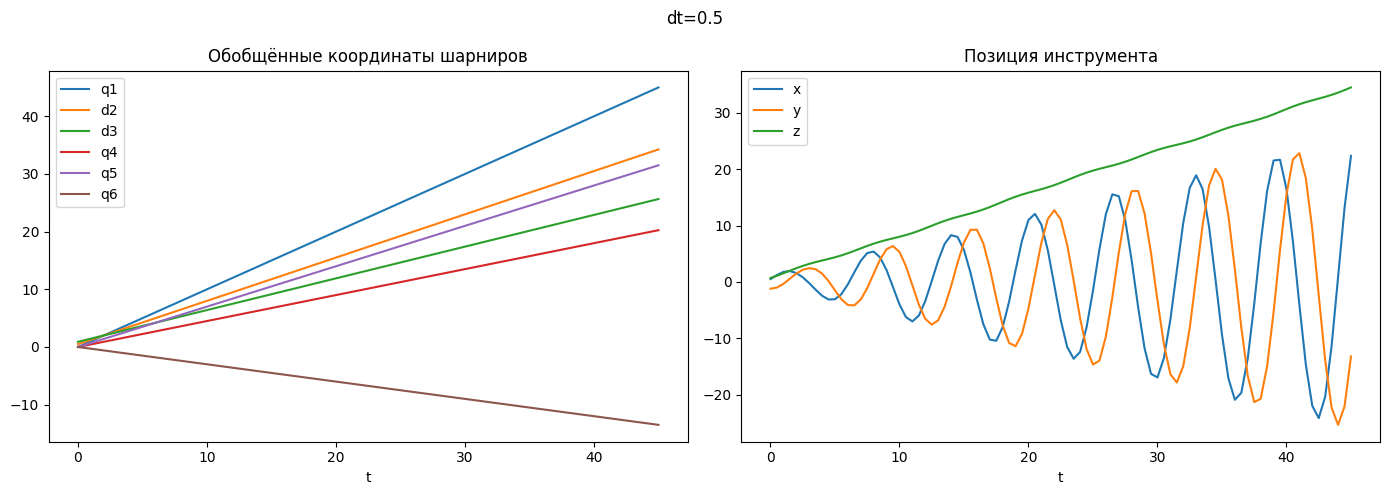

In [ ]:
q_hist, ee_hist = bot.simulate_forward_differential_kimenatics(q0, q_dot, 0.5, int(45/0.5))
plot_FDKsimulation(np.arange(len(q_hist)) * 0.5, q_hist, ee_hist, "dt=0.5")

<h4> Анализ результата:
Никаких расхождений нет, потому что вектор обобщенных скоростей это константа.
Уравнение их движения имеет вид $q(t)=q_0+\dot{q} \cdot t$
<h4> Это ODE первого порядка и метод Эйлера даёт точное решение. Что и видно на графиках. В данном случае $dt$ влияет лишь на частоту дискретизации позиции инструмента
<h4> Расхождение было бы заметно если бы скорости шарниров менялись

In [ ]:
def plot_IDKsimulation(t, q_records, ee_records, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(title)

    ax1.plot(t, q_records)
    ax1.set_title("Обобщённые координаты шарниров")
    ax1.set_xlabel("t")
    ax1.legend(['q1', 'd2', 'd3', 'q4', 'q5', 'q6'])
    ax1.grid(True)

    ax2.plot(t, ee_records)
    ax2.set_title("Положение инструмента")
    ax2.set_xlabel("t")
    ax2.set_ylabel("м")
    ax2.legend(['x', 'y', 'z'])
    ax2.grid(True)

    plt.tight_layout()
    plt.show()
q0 = [0, 1, 0.05, 0, 1, 0]
x_speeds = [0.3, 0.1, 0.0, 0.5, 0.2, 0.1]

q_rec1, ee_rec1 = bot.simulate_inverse_differential_kimenatics(q0, x_speeds, dt=0.05, steps=int(45/0.05), inversion_method="nullspace_manipulativity_damping")
q_rec2, ee_rec2 = bot.simulate_inverse_differential_kimenatics(q0, x_speeds, dt=1,  steps=int(45/1), inversion_method="nullspace_manipulativity_damping")

t1 = np.arange(len(q_rec1)) * 0.05
t2 = np.arange(len(q_rec2)) * 1

<h2>Далее приведена симуляция обратной дифференциальной кинематики при $dt=0.05$ и $dt=1$

Начальные параметры шарниров:
$q = [0, 1, 0.05, 0, 1, 0]$

Требуемая скорость инструмента:
$\dot{x} = [0.3, 0.1, 0.0, 0.5, 0.2, 0.1]$

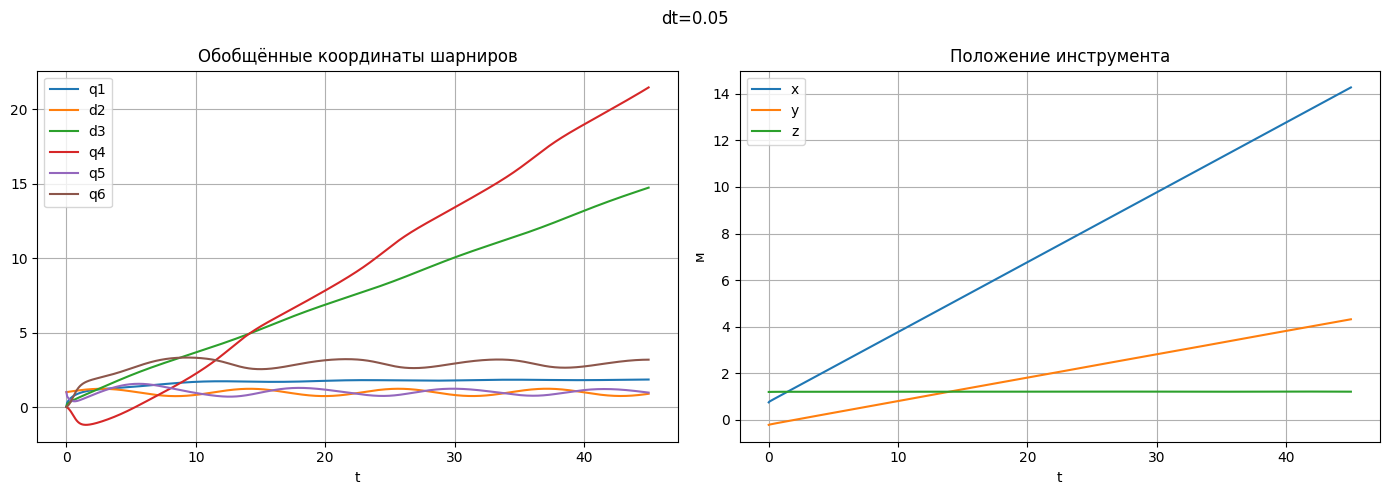

In [ ]:
plot_IDKsimulation(t1, q_rec1, ee_rec1, "dt=0.05")

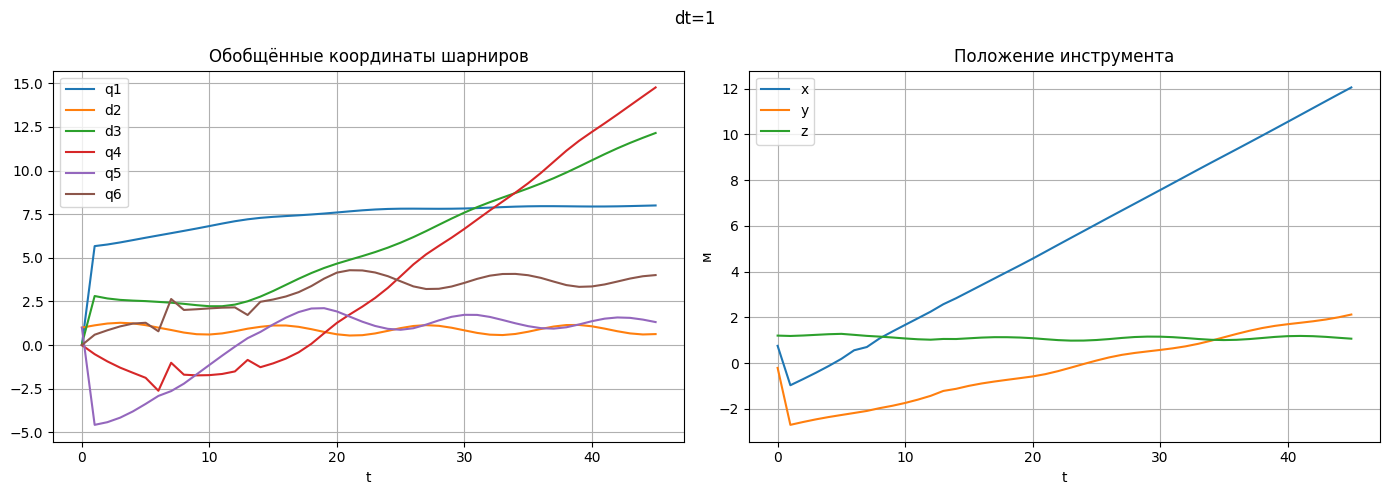

In [ ]:
plot_IDKsimulation(t2, q_rec2, ee_rec2, "dt=1")

<h4> Анализ результата:
Явно видно расхождение на несколько метров, причем заметно, что вначале робот был близок к сингулярной конфигурации и шарниры (при dt=1) сделали резкий рывок

---
<h1>Отчёт</h1>

<h2>1,2) Структурная схема и локальные системы координат </h2>

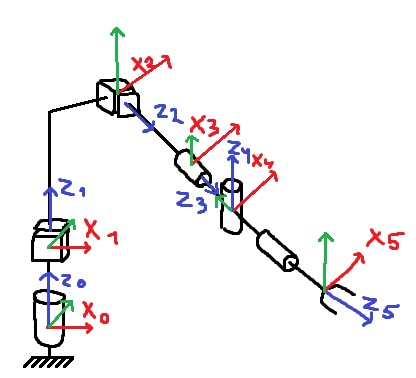

# Вычисления

## 1. Аналитическая матрица Якоби
  Для вычисления матрицы Якоби аналитически я использовал геометрический метод:
  - Для вращательных шарниров
   $$J_i=\begin{bmatrix} z_{i-1} \times (p_e - p_{i-1}) \\ z_{i-1} \end{bmatrix}$$

  - Для линейных шарниров
   $$J_i = \begin{bmatrix} z_{i-1} \\ 0 \end{bmatrix}$$


### Вычисление кодом

In [ ]:
import sympy as sp

q1, q4, q5, q6 = sp.symbols('q1 q4 q5 q6')
d0, d1, d2, d3, dg, a2 = sp.symbols('d0 d1 d2 d3 d_G a_2')

dh_params = [
    [q1, d0 + d1, 0, 0],
    [0,  d2,      a2, sp.pi/2],
    [0,  d3,      0, 0],
    [q4, 0,       0, -sp.pi/2],
    [q5, 0,       0, sp.pi/2],
    [q6, dg,      0, 0]
]

joint_types = ['R', 'L', 'L', 'R', 'R', 'R']

def dh_matrix_symbolic(theta, d, a, alpha):
    return sp.Matrix([
        [sp.cos(theta), -sp.sin(theta)*sp.cos(alpha),  sp.sin(theta)*sp.sin(alpha), a*sp.cos(theta)],
        [sp.sin(theta),  sp.cos(theta)*sp.cos(alpha), -sp.cos(theta)*sp.sin(alpha), a*sp.sin(theta)],
        [0,              sp.sin(alpha),                sp.cos(alpha),               d],
        [0,              0,                            0,                           1]
    ])

Ts = [sp.eye(4)]
for p in dh_params:
    Ts.append(Ts[-1] * dh_matrix_symbolic(*p))

pe = Ts[-1][:3, 3]
J = sp.zeros(6, 6)

for i in range(1, 7):
    z_prev = Ts[i-1][:3, 2]
    p_prev = Ts[i-1][:3, 3]

    if joint_types[i-1] == 'R':
        linear_part = z_prev.cross(pe - p_prev)
        angular_part = z_prev
    else:
        linear_part = z_prev
        angular_part = sp.Matrix([0, 0, 0])

    J[:3, i-1] = linear_part
    J[3:, i-1] = angular_part

print("J(q):")
sp.simplify(J)

J(q):


Matrix([
[-a_2*sin(q1) + d3*cos(q1) - d_G*(sin(q1)*sin(q5)*cos(q4) - cos(q1)*cos(q5)), 0,  sin(q1), -d_G*sin(q4)*sin(q5)*cos(q1), d_G*(-sin(q1)*sin(q5) + cos(q1)*cos(q4)*cos(q5)),                                         0],
[ a_2*cos(q1) + d3*sin(q1) + d_G*(sin(q1)*cos(q5) + sin(q5)*cos(q1)*cos(q4)), 0, -cos(q1), -d_G*sin(q1)*sin(q4)*sin(q5),  d_G*(sin(q1)*cos(q4)*cos(q5) + sin(q5)*cos(q1)),                                         0],
[                                                                          0, 1,        0,          d_G*sin(q5)*cos(q4),                              d_G*sin(q4)*cos(q5),                                         0],
[                                                                          0, 0,        0,                      sin(q1),                                 -sin(q4)*cos(q1), sin(q1)*cos(q5) + sin(q5)*cos(q1)*cos(q4)],
[                                                                          0, 0,        0,                     -cos(q1),           

<h3> 2. Решение сингулярности (в данном случае для примера взята сингулярность кисти):

$$q_0 = [0,0.5,1.2,0,0,0]$$
$$\dot{x} = [0,0,0,0,1,0]$$

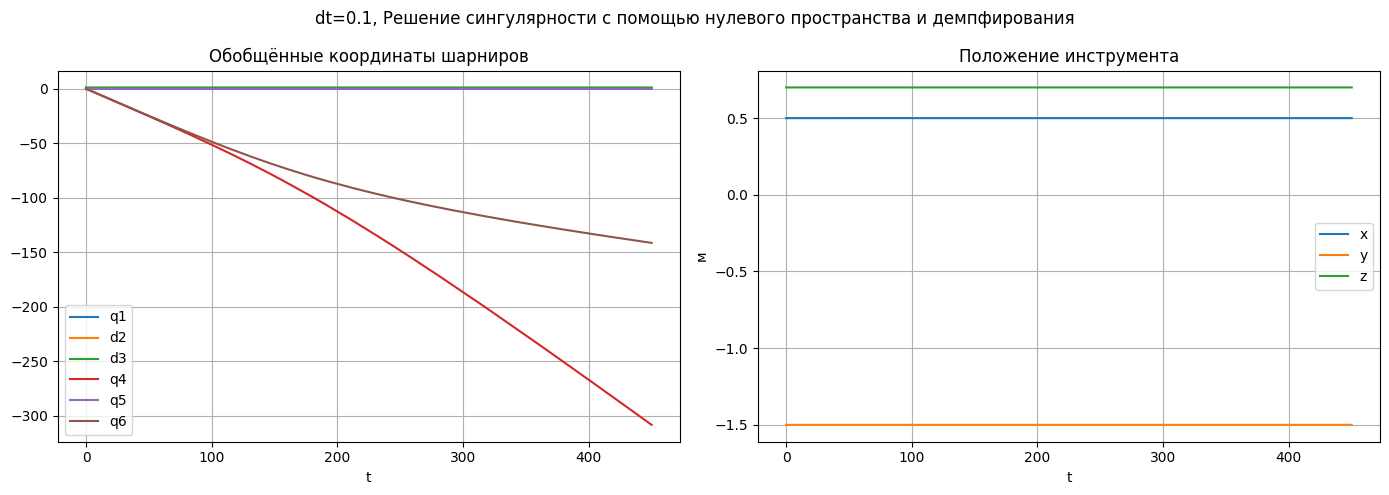

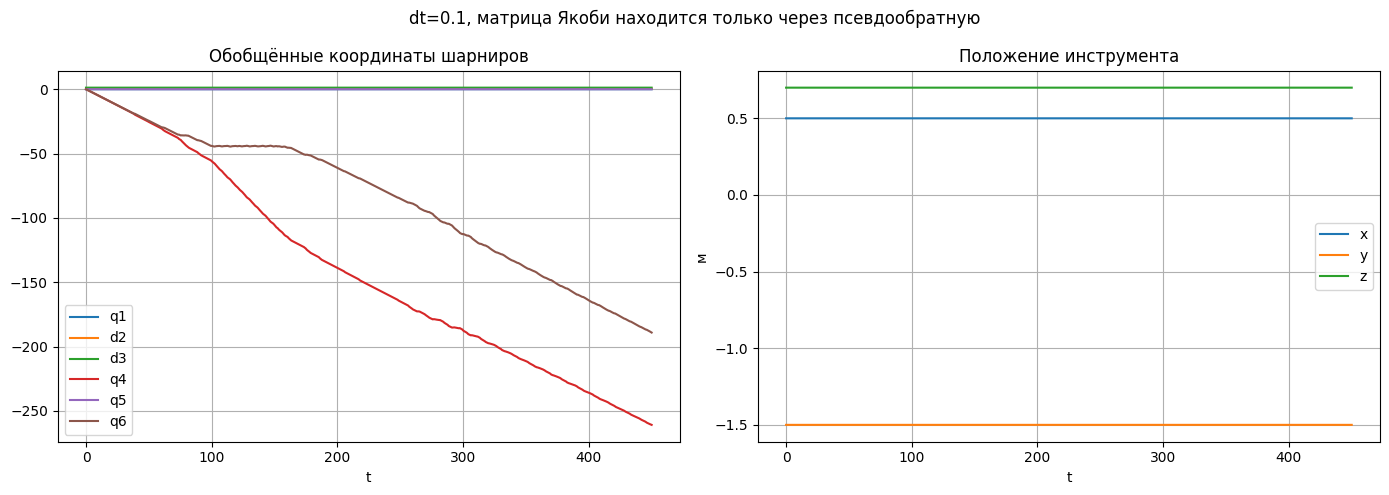

In [ ]:
q0 = [0,0.5,1.2,0,0,0]
x_speeds = [0,0,0,0,1,0]

q_hist, ee_hist = bot.simulate_inverse_differential_kimenatics(q0, x_speeds, dt=0.1, steps=int(45/0.01), inversion_method="nullspace_manipulativity_damping")
plot_IDKsimulation(np.arange(len(q_hist)) * 0.1, q_hist, ee_hist, "dt=0.1, Решение сингулярности с помощью нулевого пространства и демпфирования")

q_hist, ee_hist = bot.simulate_inverse_differential_kimenatics(q0, x_speeds, dt=0.1, steps=int(45/0.01), inversion_method="pseudoinverse")
plot_IDKsimulation(np.arange(len(q_hist)) * 0.1, q_hist, ee_hist, "dt=0.1, матрица Якоби находится только через псевдообратную")


## 3. Анализ выхода из сингулярной конфигурации.
Для выхода из сингулярной конфигурации я применил несколько методов и соеденил их:

### 1) Демпфирование матрицы Якоби. Используя метод Damped Least Squares можно избежать взрыва скоростей вблизи сингулярности, потому что слагаемое $\lambda^2 I$ будет доминировать при малом $det(JJ^T)$

$$J^* = J^T (JJ^T + \lambda^2 I)^{-1}$$

### 2) Добавлена мера манипулятивности. Её производная ищется через формулу конечной разности

$$\frac{\partial w}{\partial q_i} \approx
\frac{(\mathbf{q} + ε e_i) - w(\mathbf{q})}{ε}$$

### 3) Применена проекция на нулевое пространство и здесь же применена мера манипулятивности
$\mathbf{\dot{q}} = J^{\#} \mathbf{v} + (I - J^{\#} J) \mathbf{\dot{q}}_0$

$\dot{q}_0 = k_0 \left(\frac{\partial w}{\partial q}\right)^T$

## 4. Нахождение численной матрицы Якоби.

Для вывода линейных скоростей я использовал метод конечной разности
$$J_{P,i} = \frac{pos(q + ε e_i) - pos(q)}{ε}$$

Для нахождения угловых скоростей я воспользовался формулой из *"B. Siciliano, L. Sciavicco, L. Villani, G. Oriolo, «Robotics: Modelling, Planning and
Control», 3-е издание, Springer, 2009."* и приблизительно нашёл S с помощью метода конечной разности:

$$S = \dot{R}R^T \approx \frac{R(q + ε e_i) - R(q)}{ε} R^T(q)$$

Далее из S можно достать угловые скорости:

$$S = \begin{bmatrix} 0 & -\omega_z & \omega_y \\ \omega_z & 0 & -\omega_x \\ -\omega_y & \omega_x & 0 \end{bmatrix}$$

В течение всех вышеперечисленных тестов аналитические и численные матрицы Якоби совпадали во всех случаях

---
<h1> Блок анимации

Ниже показана анимация обратной дифференциальной кинематики робота М20П со следующими характеристиками:

$q_0 = [0, 1, 0.05, 0, 1, 0]$

$\dot{x} = [0.02, -0.05, 0.0, 0.5, 0.2, 0.1]$

$t = 45$ сек

In [ ]:
from IPython.display import HTML, Video
from matplotlib.animation import FuncAnimation
import matplotlib
from tqdm.notebook import tqdm

def generateanimation(bot, q_records, step=5, cmap='magma', path='/content/robotanim.mp4'):
    fig = plt.figure(figsize=(10.8, 10.8), facecolor='#1a1a1a')
    ax = fig.add_subplot(111, projection='3d')
    ax.set_facecolor('#1a1a1a')

    frames = len(q_records) // step
    progress = tqdm(total=frames, desc="Генерация анимации")
    tool_trail = []

    colormap = plt.get_cmap(cmap)
    n_body_segments = 4
    segment_colors = [colormap(0.3 + 0.5 * i / (n_body_segments - 1))
                      for i in range(n_body_segments)]

    def update(frame):
        ax.cla()
        ax.set_facecolor('#1a1a1a')
        q = q_records[frame * step]

        T01   = RMath.dh_matrix(q[0], bot.d0 + bot.d1, 0, 0)
        T12_1 = T01   @ RMath.dh_matrix(0, q[1], 0, 0)
        T12_2 = T12_1 @ RMath.dh_matrix(0, 0, bot.a2, np.pi/2)
        T23   = T12_2 @ RMath.dh_matrix(0, q[2], 0, 0)
        T34   = T23   @ RMath.dh_matrix(q[3], 0, 0, -np.pi/2)
        T45   = T34   @ RMath.dh_matrix(q[4], 0, 0,  np.pi/2)
        T56   = T45   @ RMath.dh_matrix(q[5], bot.d_G, 0, 0)

        p = [np.array([0,0,0]),T01[:3,3],T12_1[:3,3],T12_2[:3,3],T23[:3,3],T34[:3,3],T45[:3,3],T56[:3,3]]

        tool_trail.append(p[-1].copy())
        if len(tool_trail) > 1:
            trail = np.array(tool_trail)
            for i in range(len(trail) - 1):
                if i % 2 == 0:
                    ax.plot(trail[i:i+2, 0], trail[i:i+2, 1], trail[i:i+2, 2],'-', lw=1, color='#FFFFFF', alpha=1)

        body_segments = [(p[0], p[1]), (p[1], p[2]), (p[2], p[3]), (p[3], p[4])]
        for seg, color in zip(body_segments, segment_colors):
            pts = np.array(seg)
            ax.plot(pts[:,0],pts[:,1],pts[:,2],'-',lw=8,color=color,solid_capstyle='round',solid_joinstyle='round')

        tool = np.array(p[6:])
        ax.plot(tool[:,0], tool[:,1], tool[:,2],'-', lw=6, color='#444444',solid_capstyle='round', solid_joinstyle='round')

        scale = 0.3
        ax.quiver(*p[-1], *T56[:3,0], length=scale, color='#ef5350', lw=2, arrow_length_ratio=0.25)
        ax.quiver(*p[-1], *T56[:3,1], length=scale, color='#66bb6a', lw=2, arrow_length_ratio=0.25)
        ax.quiver(*p[-1], *T56[:3,2], length=scale, color='#42a5f5', lw=2, arrow_length_ratio=0.25)

        x, y, z = p[-1]
        ax.text2D(0.02, 0.95, f"Позиция инструмента: ({x:.3f}, {y:.3f}, {z:.3f})",transform=ax.transAxes, color='white',fontsize=9)

        ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_zlim(0, 3)
        ax.set_xlabel('X', color='#666'); ax.set_ylabel('Y', color='#666')
        ax.set_zlabel('Z', color='#666')
        ax.tick_params(colors='#444')
        for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
            pane.fill = False
            pane.set_edgecolor('#2a2a2a')
        ax.grid(True, color='#2a2a2a', linewidth=0.5)
        ax.set_title(f"{frame * step} / {len(q_records)}",
                     color='#aaaaaa', fontsize=10)
        progress.update(1)

    anim = FuncAnimation(fig, update, frames=frames, interval=50)
    plt.close()

    writer = matplotlib.animation.FFMpegWriter(fps=30)
    anim.save(path, writer=writer, dpi=200)
    progress.close()

    return Video(path, embed=True, width=800)

q0 = [0, 1, 0.05, 0, 1, 0]
x_speeds = [0.02, -0.05, 0.0, 0.5, 0.2, 0.1]
q_records_anim, _ = bot.simulate_inverse_differential_kimenatics(q0, x_speeds, dt=0.05, steps=int(45/0.05), inversion_method="nullspace_manipulativity_damping")
generateanimation(bot, q_records_anim, step=10, cmap='inferno')

Генерация анимации:   0%|          | 0/90 [00:00<?, ?it/s]